In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
def power_law(m, A, alpha):
    return A * m**alpha

In [18]:
def compute_cumulative_outcome_fractions(df, masses, N):
    """
    df      : DataFrame with columns ['mass', 'time', 'particle_id', 'result']
              where result is 'Ejected' or 'Captured', and each row represents
              the time at which that particle's outcome occurred
    masses  : list/array of unique mass values, in the same order as N
    N       : list/array of total particle counts, one per mass in `masses`

    Returns
    -------
    ejection_df, capture_df : DataFrames indexed by mass, columns = sorted
                               unique time values, entries = CUMULATIVE
                               fraction of N with that result by that time
                               (i.e. fraction ejected/captured at or before
                               each time, monotonically non-decreasing
                               across each row)
    """
    if len(masses) != len(N):
        raise ValueError("masses and N must be the same length")

    mass_to_N = dict(zip(masses, N))

    times = np.sort(df["time"].unique())

    ejection_df = pd.DataFrame(index=masses, columns=times, dtype=float)
    capture_df = pd.DataFrame(index=masses, columns=times, dtype=float)

    for mass in masses:
        mass_df = df[df["mass"] == mass]
        denom = mass_to_N[mass]

        counts = (
            mass_df.groupby(["time", "result"])
            .size()
            .unstack(fill_value=0)
        )

        # reindex to the full sorted time axis, filling any missing times
        # with 0 new outcomes at that time, then cumsum across time
        ejected_counts = counts.get("Ejected", pd.Series(0, index=counts.index))
        captured_counts = counts.get("Captured", pd.Series(0, index=counts.index))

        ejected_counts = ejected_counts.reindex(times, fill_value=0)
        captured_counts = captured_counts.reindex(times, fill_value=0)

        ejection_df.loc[mass] = (ejected_counts.cumsum() / denom).values
        capture_df.loc[mass] = (captured_counts.cumsum() / denom).values

    return ejection_df, capture_df

In [19]:
def get_ejected_initial_conditions_unordered(initial_df, final_df, mass):
    ejected_ids = final_df.loc[
        (final_df["mass"] == mass) &
        (final_df["result"] == "Ejected"),
        "particle_id"
    ].unique()

    return initial_df[
        initial_df["particle_id"].isin(ejected_ids)
    ].copy()

In [20]:
df_1=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2188349_ejection_results.txt', header=None)
df_1_lm_1=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2215154_ejection_results.txt', header=None)
df_1_lm_2=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results_Restarted/2215154/2215154_mass_7.94328235e-05_restarted_results.txt', header=None)

In [111]:
df_other_mass=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results_Restarted/2215154/2215154_mass_3.98107171e-05_restarted_results.txt')

In [112]:
df_other_mass.columns = ['mass', 'time', 'result', 'particle_id']

In [113]:
df_1_other_mass=pd.concat([df_1_lm_1,df_other_mass])

In [115]:
df_1_other_mass.mass.unique()

array([1.58489319e-04, 7.94328235e-05, 3.98107171e-05, 1.99526231e-05,
       1.00000000e-05, 3.98107171e-05])

In [125]:
target = 3.98107171e-05

df_1_other_mass.loc[np.isclose(df_1_other_mass['mass'], target), 'mass'] = target

In [128]:
ejection_df_other_mass, c=compute_cumulative_outcome_fractions(df_1_other_mass, df_1_other_mass.mass.unique(),[800,800,800,800,800])

In [129]:
ejection_df_other_mass

,0.000000e+00,3.099754e+04,3.799849e+04,7.899374e+04,7.999366e+04,1.219976e+05,1.719864e+05,3.429932e+05,4.239664e+05,4.339828e+05,...,1.014380e+07,1.046879e+07,1.049579e+07,1.051679e+07,1.058079e+07,1.061079e+07,1.068679e+07,1.085978e+07,1.090778e+07,1.115578e+07
0.000158,0.0,0.00125,0.00125,0.00125,0.00125,0.00125,0.00250,0.00250,0.00375,0.00375,...,0.27875,0.27875,0.27875,0.27875,0.27875,0.27875,0.27875,0.27875,0.27875,0.27875
0.000079,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00125,...,0.23500,0.23500,0.23500,0.23500,0.23500,0.23500,0.23500,0.23500,0.23500,0.23500
0.000040,0.0,0.00000,0.00000,0.00000,0.00000,0.00125,0.00125,0.00125,0.00125,0.00125,...,0.06250,0.06375,0.06500,0.06625,0.06750,0.06875,0.07000,0.07125,0.07250,0.07375
0.000020,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.01250,0.01250,0.01250,0.01250,0.01250,0.01250,0.01250,0.01250,0.01250,0.01250
0.000010,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.00625,0.00625,0.00625,0.00625,0.00625,0.00625,0.00625,0.00625,0.00625,0.00625


In [131]:
ejection_df_other_mass.index

Index([    0.0001584893192461,         7.94328235e-05,         3.98107171e-05,
       1.9952623149688783e-05,                  1e-05],
      dtype='float64')

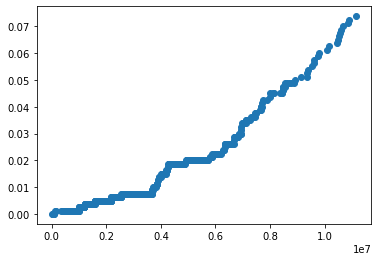

In [132]:
plt.scatter(ejection_df_other_mass.columns,ejection_df_other_mass.loc[ejection_df_other_mass.index[2]])

In [119]:
ejection_df_other_mass.iloc[-1]

AttributeError: 'tuple' object has no attribute 'iloc'

In [41]:
df_1.columns = ['mass', 'time', 'result', 'particle_id']
df_1_lm_1.columns = ['mass', 'time', 'result', 'particle_id']
df_1_lm_2.columns= ['mass', 'time', 'result', 'particle_id']

In [42]:
df_1_lm=pd.concat([df_1_lm_1,df_1_lm_2])

In [43]:
target = 7.94328235e-05

df_1_lm.loc[np.isclose(df_1_lm['mass'], target), 'mass'] = target

In [97]:
df_i_5=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Particle_Tracking/2215154-3_initial_particles.txt',header=None)
df_i_2=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Particle_Tracking/2215154-4_initial_particles.txt',header=None)
#these numbers are pretty much meaingless atp

In [98]:
df_i_5.columns=['a','e','particle_id']

In [99]:
df_i_2.columns=['a','e','particle_id']

In [100]:
df_1_lm.mass.unique()

array([1.58489319e-04, 7.94328235e-05, 3.98107171e-05, 1.99526231e-05,
       1.00000000e-05])

In [101]:
df_i_5

,a,e,particle_id
0,0.937835,0.033010,24
1,1.407096,0.068243,27
2,1.766053,0.094003,28
3,1.071556,0.102268,26
4,0.855573,0.044922,30
...,...,...,...
795,0.983252,0.191157,737
796,1.655451,0.108620,772
797,1.029333,0.191388,738
798,1.775769,0.135724,769


In [102]:
df_e=get_ejected_initial_conditions_unordered(df_i_5,df_1_lm,df_1_lm.mass.unique()[1] )
df_e_2=get_ejected_initial_conditions_unordered(df_i_2,df_1_lm,df_1_lm.mass.unique()[0] )

In [103]:
df_e

,a,e,particle_id
0,0.937835,0.033010,24
3,1.071556,0.102268,26
6,0.953876,0.076813,7
8,1.040888,0.022477,1
11,1.088907,0.210922,2
...,...,...,...
785,1.462501,0.270513,736
786,0.851240,0.118058,674
787,1.046182,0.140756,705
795,0.983252,0.191157,737


In [89]:
df_1_lm_first=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2186705_ejection_results.txt', header=None)

In [90]:
first_lm_i_4=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Particle_Tracking/2186705-4_initial_particles.txt', header=None)

In [91]:
first_lm_i_4.columns=['a','e','id']

(array([ 1.,  0.,  4.,  3., 10.,  7.,  5., 12.,  9., 14., 15.,  4.,  8.,
        14.,  6., 11.,  7., 14.,  8., 13.,  3.,  5.,  9.,  3., 10.,  1.,
         6.,  5.,  4.,  6.,  0.,  2.,  0.,  0.,  1.,  0.,  2.,  0.,  0.,
         1.]),
 array([0.74336061, 0.76550091, 0.78764122, 0.80978152, 0.83192182,
        0.85406213, 0.87620243, 0.89834274, 0.92048304, 0.94262335,
        0.96476365, 0.98690395, 1.00904426, 1.03118456, 1.05332487,
        1.07546517, 1.09760547, 1.11974578, 1.14188608, 1.16402639,
        1.18616669, 1.20830699, 1.2304473 , 1.2525876 , 1.27472791,
        1.29686821, 1.31900852, 1.34114882, 1.36328912, 1.38542943,
        1.40756973, 1.42971004, 1.45185034, 1.47399064, 1.49613095,
        1.51827125, 1.54041156, 1.56255186, 1.58469216, 1.60683247,
        1.62897277]),
 <BarContainer object of 40 artists>)

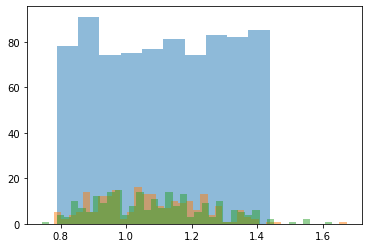

In [104]:
plt.hist(first_lm_i_4.a, alpha=0.5)
plt.hist(df_e.a,alpha=0.5, bins=40)
plt.hist(df_e_2.a,alpha=0.5, bins=40)

In [71]:
ejection_df_1, capture_df_1 = compute_cumulative_outcome_fractions(df_1, df_1.mass.unique(), N=[800,800,800,800,800,800])
ejection_df_1_lm,capture_df_1_lm=compute_cumulative_outcome_fractions(df_1_lm,df_1_lm.mass.unique(), N=[800,800,800,800,800])

In [105]:
# Original (wider) interval, inferred from original initial particles
a_old_min = first_lm_i_4["a"].min()
a_old_max = first_lm_i_4["a"].max()
width_old = a_old_max - a_old_min

# Match each recent mass to its initial conditions
# These associations follow your existing df_e / df_e_2 definitions.
recent_runs = {
    df_1_lm.mass.unique()[1]: df_i_5,
    df_1_lm.mass.unique()[0]: df_i_2,
}

comparison_rows = []

for mass, initial_df in recent_runs.items():

    # Actual sampled interval in the recent run
    a_new_min = initial_df["a"].min()
    a_new_max = initial_df["a"].max()
    width_new = a_new_max - a_new_min

    # Recent ejections for this planetary mass
    ejections = df_1_lm.loc[
        np.isclose(df_1_lm["mass"], mass, rtol=1e-8, atol=0)
        & (df_1_lm["result"] == "Ejected"),
        ["particle_id", "time"]
    ].copy()

    # Each particle should appear only once as an ejection
    if ejections["particle_id"].duplicated().any():
        raise ValueError(f"Duplicate ejection IDs for mass {mass}")

    if initial_df["particle_id"].duplicated().any():
        raise ValueError(f"Duplicate initial particle IDs for mass {mass}")

    # Join every ejection to its original semimajor axis
    ejected_initial = ejections.merge(
        initial_df[["particle_id", "a", "e"]],
        on="particle_id",
        how="left",
        validate="one_to_one"
    )

    if ejected_initial["a"].isna().any():
        raise ValueError(
            f"Some ejected particles lack initial conditions for mass {mass}"
        )

    # Ejections the original interval would have excluded
    outside = (
        (ejected_initial["a"] < a_old_min) |
        (ejected_initial["a"] > a_old_max)
    )

    n_ejected = len(ejected_initial)
    n_outside = outside.sum()
    n_inside = n_ejected - n_outside

    N = len(initial_df)

    # Fraction normalized to original interval, assuming Sigma ~ 1/a
    scale = width_new / width_old

    f_raw = n_ejected / N
    f_normalized = f_raw * scale

    # Contribution from particles outside the original interval
    f_outside = (n_outside / N) * scale

    # Fraction after excluding ejections outside original interval
    f_inside_only = (n_inside / N) * scale

    comparison_rows.append({
        "mass": mass,
        "old_interval": (a_old_min, a_old_max),
        "new_interval": (a_new_min, a_new_max),
        "width_ratio": scale,
        "N_initial": N,
        "N_ejected": n_ejected,
        "N_outside_old": n_outside,
        "outside_percent": (
            100 * n_outside / n_ejected if n_ejected else 0
        ),
        "f_raw": f_raw,
        "f_normalized": f_normalized,
        "f_outside": f_outside,
        "f_inside_only": f_inside_only,
    })

comparison = pd.DataFrame(comparison_rows).set_index("mass")

display(comparison.T)

mass,0.000079,0.000158
old_interval,"(0.7882883679766359, 1.438186663441487)","(0.7882883679766359, 1.438186663441487)"
new_interval,"(0.6011990962584977, 1.999799604926292)","(0.6005788489298914, 1.9994693333245523)"
width_ratio,2.15203,2.152476
N_initial,800,800
N_ejected,214,223
N_outside_old,5,6
outside_percent,2.336449,2.690583
f_raw,0.2675,0.27875
f_normalized,0.575668,0.600003
f_outside,0.01345,0.016144


In [109]:
f_old = 0.18  # Original ejection fraction
f_new = 0.27  # Recent raw ejection fraction

N_old = 800
N_new = 800
scale = 0.7

f_new_scaled = scale * f_new

sigma_old = np.sqrt(f_old * (1 - f_old) / N_old)
sigma_new = scale * np.sqrt(f_new * (1 - f_new) / N_new)

z = abs(f_old - f_new_scaled) / np.hypot(sigma_old, sigma_new)

print(f"Difference: {abs(f_old - f_new_scaled):.4f}")
print(f"Combined 1σ uncertainty: {np.hypot(sigma_old, sigma_new):.4f}")
print(f"Discrepancy: {z:.2f}σ")

Difference: 0.0090
Combined 1σ uncertainty: 0.0175
Discrepancy: 0.52σ


In [72]:
files=[
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_0.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_1.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_2.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_3.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_4.csv',
    '/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/remaining_particles_2188349_5.csv',

]

In [73]:
remaining_df_1=pd.DataFrame()
for file in files:
    temp_df=pd.read_csv(file)
    print(temp_df)
    remaining_df_1=pd.concat([remaining_df_1,temp_df], ignore_index=True)

     m_planet           time                   a         e
0        0.01  231843.665319  0.5089722881201106  0.084216
1        0.01  231843.665319   0.620409418940917  0.035911
2        0.01  231843.665319  2.3822393205381274  0.086349
3        0.01  231843.665319  2.0986857079055286  0.079524
4        0.01  231843.665319  1.5648132883096946  0.063681
..        ...            ...                 ...       ...
342      0.01  231843.665319  2.0449604034765905  0.207570
343      0.01  231843.665319  1.8606264991877275  0.081027
344      0.01  231843.665319  2.2857738984481473  0.125663
345      0.01  231843.665319   1.975885280915687  0.071762
346      0.01  231843.665319    2.37385280310965  0.249165

[347 rows x 4 columns]
     m_planet           time                   a         e
0    0.005012  278303.460942  1.9177560825596134  0.162057
1    0.005012  278303.460942  2.4896096587038623  0.094540
2    0.005012  278303.460942  2.2594893075761946  0.151854
3    0.005012  278303.460942    

In [103]:
left_counts = ejection_df_1[ejection_df_1.columns[-1]]*800

unbound_counts = (
    remaining_df_1.groupby("m_planet")["a"]
    .apply(lambda x: (x == "Unbound").sum())
)


total_affected = left_counts.add(unbound_counts, fill_value=0)

In [106]:
left_counts

0.002512    303.0
0.000631    196.0
0.010000    447.0
0.005012    322.0
0.001259    235.0
0.000316    169.0
Name: 2019680.6856863664, dtype: float64

In [104]:
fit_fracs_unscaled=pd.concat([total_affected/800,ejection_df_1_lm[ejection_df_1_lm.columns[-1]]])
fit_fracs_unscaled.sort_index(inplace=True,ascending=False)

In [105]:
fit_fracs_unscaled

0.010000    0.57000
0.005012    0.42250
0.002512    0.39125
0.001259    0.29875
0.000631    0.25000
0.000316    0.21125
0.000158    0.27875
0.000079    0.26750
0.000040    0.04500
0.000020    0.01250
0.000010    0.00625
dtype: float64

In [95]:
fit_fracs=fit_fracs_unscaled
fit_fracs = fit_fracs.iloc[:-3]

In [96]:
fit_fracs.loc[fit_fracs.index < 0.0003] *= 0.7

In [97]:
fit_fracs

0.010000    0.570000
0.005012    0.422500
0.002512    0.391250
0.001259    0.298750
0.000631    0.250000
0.000316    0.211250
0.000158    0.195125
0.000079    0.187250
dtype: float64

In [98]:
popt,pcov=curve_fit(power_law,fit_fracs.index,fit_fracs)

In [100]:
fit_fracs_lower_error=np.sqrt(((1-fit_fracs)*fit_fracs)/800)
fit_fracs_upper_error=fit_fracs_lower_error+0.04/3

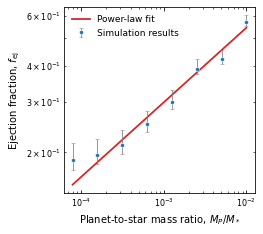

In [101]:
# plt.scatter(fit_fracs.index,fit_fracs)
cm = 1/2.54  # centimeters in inches
fig, ax = plt.subplots(1, 1, tight_layout=False,figsize=(8.7*cm,8.7*cm),sharex=False,sharey=False
                       ,gridspec_kw={'hspace': 0.35, 'wspace': 0.3})

# Data and asymmetric error bars
ax.errorbar(
    fit_fracs.index,
    fit_fracs,
    yerr=[fit_fracs_lower_error, fit_fracs_upper_error],
    fmt='o',
    markersize=4,
    color='tab:blue',
    ecolor='gray',
    elinewidth=0.8,
    capsize=2,
    capthick=0.8,
    markeredgecolor='white',
    markeredgewidth=0.5,
    label='Simulation results',
    zorder=3
)

# Power-law fit
x = np.logspace(-4.1, -2, 300)
a, b = popt
y = power_law(x, a, b)

ax.plot(
    x, y,
    color='tab:red',
    linewidth=1.8,
    label='Power-law fit',
    zorder=2
)

# Logarithmic axes
ax.set_xscale('log')
ax.set_yscale('log')


ax.set_xlabel(r'Planet-to-star mass ratio, $M_P/M_*$', fontsize=10)
ax.set_ylabel(r'Ejection fraction, $f_{\mathrm{ej}}$', fontsize=10)

# Ticks
ax.tick_params(
    axis='both',
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=8
)

ax.minorticks_on()

# Subtle horizontal grid
ax.grid(
    axis='y',
    which='major',
    linestyle=':',
    alpha=0.25
)

ax.legend(frameon=False, fontsize=9)

# ax.set_yticks([0.2, 0.3, 0.4, 0.5, 0.6])
# ax.set_yticklabels(['0.2', '0.3', '0.4', '0.5', '0.6'])

#fig.tight_layout()
#plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/f_ej_fit_errorbars.png', facecolor='white',bbox_inches='tight', dpi=500)

q = 7.943e-05: 214 ejected, 800 initialized
q = 1.585e-04: 223 ejected, 800 initialized


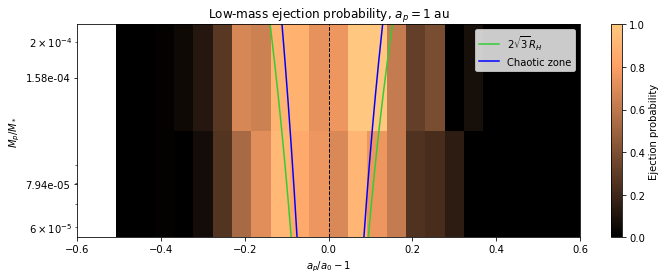

In [110]:

import numpy as np
import matplotlib.pyplot as plt

a_planet = 1.0
n_bins = 26
x_edges = np.linspace(-0.6, 0.6, n_bins + 1)

# Same two mass / initial-condition associations as your notebook
runs = [
    (df_1_lm.mass.unique()[1], df_i_5),
    (df_1_lm.mass.unique()[0], df_i_2),
]

mass_values = []
P = []

for mass, df_i in runs:

    # Ejected particle IDs for this mass
    ejected_ids = df_1_lm.loc[
        np.isclose(df_1_lm.mass, mass, rtol=1e-8, atol=0)
        & (df_1_lm.result == "Ejected"),
        "particle_id"
    ].unique()

    df = df_i.copy()
    df["ejected"] = df.particle_id.isin(ejected_ids)
    df["x"] = a_planet / df.a - 1

    # Number of initialized and ejected particles in each bin
    N_all, _ = np.histogram(df.x, bins=x_edges)
    N_ej, _ = np.histogram(
        df.loc[df.ejected, "x"],
        bins=x_edges
    )

    p = np.divide(
        N_ej, N_all,
        out=np.full(len(N_all), np.nan),
        where=N_all > 0
    )

    mass_values.append(mass)
    P.append(p)

    print(
        f"q = {mass:.3e}: "
        f"{len(ejected_ids)} ejected, "
        f"{len(df)} initialized"
    )

mass_values = np.array(mass_values)
P = np.array(P)

# Sort masses for plotting
order = np.argsort(mass_values)
mass_values = mass_values[order]
P = P[order]

# Logarithmic mass-bin boundaries
log_m = np.log10(mass_values)
mid = (log_m[0] + log_m[1]) / 2

mass_edges = 10**np.array([
    log_m[0] - (mid - log_m[0]),
    mid,
    log_m[1] + (log_m[1] - mid)
])

fig, ax = plt.subplots(figsize=(10, 4))

mesh = ax.pcolormesh(
    x_edges,
    mass_edges,
    P,
    shading="flat",
    cmap="copper",
    vmin=0,
    vmax=1
)

ax.set_yscale("log")
ax.axvline(0, color="black", ls="--", lw=1)

# Same chaotic-zone and Hill-radius curves as your notebook
q = np.logspace(
    np.log10(mass_edges.min()),
    np.log10(mass_edges.max()),
    200
)

R_H = a_planet * (q / (3 * (1 + q)))**(1/3)

x_H_inner = a_planet / (a_planet - R_H) - 1
x_H_outer = a_planet / (a_planet + R_H) - 1

R_CZ_inner = 1.2 * q**0.28 * a_planet
R_CZ_outer = 1.7 * q**0.31 * a_planet

x_CZ_inner = a_planet / (a_planet - R_CZ_inner) - 1
x_CZ_outer = a_planet / (a_planet + R_CZ_outer) - 1

ax.plot(
    2*np.sqrt(3)*x_H_inner, q,
    color="limegreen", label=r"$2\sqrt{3}R_H$"
)
ax.plot(
    2*np.sqrt(3)*x_H_outer, q,
    color="limegreen"
)

ax.plot(
    x_CZ_inner, q,
    color="blue", label="Chaotic zone"
)
ax.plot(
    x_CZ_outer, q,
    color="blue"
)

ax.set_xlim(-0.6, 0.6)
ax.set_ylim(mass_edges.min(), mass_edges.max())
ax.set_yticks(mass_values)
ax.set_yticklabels([f"{m:.2e}" for m in mass_values])

ax.set_xlabel(r"$a_p/a_0 - 1$")
ax.set_ylabel(r"$M_p/M_*$")
ax.set_title(r"Low-mass ejection probability, $a_p=1$ au")

fig.colorbar(mesh, ax=ax, label="Ejection probability")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()
